# Student Academic Risk Assessment Model


In [89]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

from collections import Counter
from pathlib import Path
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

HERE = Path.cwd().resolve()
candidates = [HERE, *HERE.parents]
RISK_ASSESSMENT_DIR = next(
    (p for p in candidates if p.name == "RiskAssessment" and (p / "model.py").is_file()),
    None,
)
if RISK_ASSESSMENT_DIR is None:
    RISK_ASSESSMENT_DIR = next(
        (p / "RiskAssessment" for p in candidates if (p / "RiskAssessment" / "model.py").is_file()),
        None,
    )
if RISK_ASSESSMENT_DIR is None:
    raise FileNotFoundError("Could not find python/RiskAssessment/model.py from the current directory.")

PYTHON_DIR = RISK_ASSESSMENT_DIR.parent
DATA_DIR = PYTHON_DIR / "data"
TRAINING_FILE = DATA_DIR / "student_academic_risk.csv"
MODEL_DIR = RISK_ASSESSMENT_DIR / "ModelOutput"
MODEL_FILE = MODEL_DIR / "risk_model.joblib"

FEATURES = [
    "previous_gpa", "attendance", "assignment_score", "quiz_score",
    "study_hours", "engagement_score", "late_assignments",
    "completed_assignments", "learning_progress",
]
ENGINEERED_FEATURES = [
    "score_avg", "gpa_x_attendance", "progress_gap", "late_ratio", "performance_index",
]
MODEL_FEATURES = FEATURES + ENGINEERED_FEATURES
TARGET = "academic_risk_level"
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("=" * 72)
print("ACADEMIC RISK MODEL CONFIGURATION")
print("=" * 72)
print(f"Training data : {TRAINING_FILE}")
print(f"Model output  : {MODEL_FILE}")
print(f"Test fraction : {TEST_SIZE:.0%}")
print(f"Random seed   : {RANDOM_STATE}")
print(f"Total features: {len(MODEL_FEATURES)}")

ACADEMIC RISK MODEL CONFIGURATION
Training data : D:\Research\new\EduPulse\EduPulse\python\data\student_academic_risk.csv
Model output  : D:\Research\new\EduPulse\EduPulse\python\RiskAssessment\ModelOutput\risk_model.joblib
Test fraction : 20%
Random seed   : 42
Total features: 14


In [90]:
# ============================================================
# LOAD AND EXPLORE DATA
# ============================================================

if not TRAINING_FILE.is_file():
    raise FileNotFoundError(
        f"Training CSV not found: {TRAINING_FILE}. Place student_academic_risk.csv in python/data/."
    )
data = pd.read_csv(TRAINING_FILE)
print(f"Loaded {len(data):,} rows and {len(data.columns)} columns.")
print("Columns:", list(data.columns))
print("\nPreview:")
display(data.head())
print("\nRisk label distribution (including missing labels):")
display(
    data["academic_risk_level"].value_counts(dropna=False)
    if "academic_risk_level" in data else "Target column missing"
)
print("\nMissing values in model columns:")
display(data.reindex(columns=FEATURES + [TARGET]).isna().sum())


Loaded 50,000 rows and 11 columns.
Columns: ['student_id', 'previous_gpa', 'attendance', 'assignment_score', 'quiz_score', 'study_hours', 'engagement_score', 'late_assignments', 'completed_assignments', 'learning_progress', 'academic_risk_level']

Preview:


,student_id,previous_gpa,attendance,assignment_score,quiz_score,study_hours,engagement_score,late_assignments,completed_assignments,learning_progress,academic_risk_level
0,STU00001,3.00,90.3,43.2,61.4,43.8,52.6,3,10,62.4,Low
1,STU00002,2.12,48.5,100.0,51.4,7.8,73.0,6,8,65.6,Low
2,STU00003,3.29,74.2,100.0,74.0,9.1,53.9,2,3,70.9,Low
3,STU00004,3.41,60.5,55.9,79.0,9.1,38.5,1,2,40.0,Low
4,STU00005,1.53,100.0,97.2,76.7,5.5,82.5,2,8,88.3,Low



Risk label distribution (including missing labels):


academic_risk_level
Low       36711
Medium    12138
High       1151
Name: count, dtype: int64


Missing values in model columns:


previous_gpa             0
attendance               0
assignment_score         0
quiz_score               0
study_hours              0
engagement_score         0
late_assignments         0
completed_assignments    0
learning_progress        0
academic_risk_level      0
dtype: int64

## Check the training data

In [91]:
# ============================================================
# VALIDATE AND PREPARE BASE FEATURES
# ============================================================

missing_columns = [c for c in FEATURES + [TARGET] if c not in data.columns]
if missing_columns:
    raise ValueError(f"Training CSV is missing required columns: {missing_columns}")

label_map = {"low": "Low", "medium": "Medium", "high": "High"}
raw_labels = data[TARGET].astype("string").str.strip().str.lower()
labels = raw_labels.map(label_map)
unknown = sorted(raw_labels[labels.isna() & raw_labels.notna()].unique().tolist())
if unknown:
    raise ValueError(f"Unexpected risk labels in {TARGET}: {unknown}")
if labels.isna().any():
    n_missing = int(labels.isna().sum())
    raise ValueError(f"Target {TARGET} contains {n_missing} missing label(s).")

X_base = data[FEATURES].apply(pd.to_numeric, errors="coerce")
for column in FEATURES:
    invalid = data[column].notna() & X_base[column].isna()
    if invalid.any():
        raise ValueError(f"Feature {column!r} has {int(invalid.sum())} non-numeric value(s).")
y = labels
class_counts = y.value_counts()
if len(class_counts) != 3:
    raise ValueError(f"Expected all 3 risk levels; found: {class_counts.to_dict()}")
if class_counts.min() < 2:
    raise ValueError("Each risk level needs at least two rows for a stratified split.")

print(f"Usable rows: {len(X_base):,}")
print("Class distribution:")
display(class_counts.rename_axis("risk_level").to_frame("rows"))


Usable rows: 50,000
Class distribution:


,rows
risk_level,
Low,36711
Medium,12138
High,1151


In [92]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

def add_engineered_features(df):
    df = df.copy()
    df["score_avg"]         = (df["assignment_score"] + df["quiz_score"]) / 2
    df["gpa_x_attendance"]  = df["previous_gpa"] * df["attendance"] / 100
    df["progress_gap"]      = df["learning_progress"] - df["score_avg"]
    df["late_ratio"]        = df["late_assignments"] / df["completed_assignments"].clip(lower=1)
    df["performance_index"] = df["score_avg"] * df["attendance"] / 100 * df["learning_progress"] / 100
    return df

data_eng = add_engineered_features(X_base.join(y.rename("risk_level")))
X = data_eng[MODEL_FEATURES]

print("Engineered feature means by risk level:")
display(data_eng[ENGINEERED_FEATURES + ["risk_level"]].groupby("risk_level").mean())


Engineered feature means by risk level:


,score_avg,gpa_x_attendance,progress_gap,late_ratio,performance_index
risk_level,,,,,
High,52.156603,1.624921,-1.576672,0.752736,17.036660
Low,71.824170,2.258916,-5.143170,0.696015,38.766467
Medium,61.109750,1.896384,-2.932456,0.742161,25.551959


In [93]:
# ============================================================
# STRATIFIED TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}")
print(f"Test rows    : {len(X_test):,}")
print("\nTraining label proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion"))
print("Test label proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion"))


Training rows: 40,000
Test rows    : 10,000

Training label proportions:


academic_risk_level
High      0.023025
Low       0.734225
Medium    0.242750
Name: proportion, dtype: float64

Test label proportions:


academic_risk_level
High      0.0230
Low       0.7342
Medium    0.2428
Name: proportion, dtype: float64

In [94]:
# ============================================================
# TRAIN AND EVALUATE LIGHTGBM
# ============================================================

# Compute balanced class weights from training distribution
counts = Counter(y_train)
total = len(y_train)
class_weight = {cls: total / (3 * cnt) for cls, cnt in counts.items()}
print("Computed class weights:", class_weight)

def make_model(class_weight=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", lgb.LGBMClassifier(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=10,
            num_leaves=127,
            min_child_samples=5,
            subsample=0.8,
            colsample_bytree=0.8,
            class_weight=class_weight,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )),
    ])

evaluation_model = make_model(class_weight=class_weight)
evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)
y_train_pred = evaluation_model.predict(X_train)

accuracy = accuracy_score(y_test, y_pred)
train_accuracy = accuracy_score(y_train, y_train_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print("=" * 72)
print("HELD-OUT EVALUATION")
print("=" * 72)
print(f"Training accuracy : {train_accuracy:.4f}")
print(f"Test accuracy     : {accuracy:.4f}")
print(f"Macro F1          : {macro_f1:.4f} (each risk level has equal weight)")
print(f"Weighted F1       : {weighted_f1:.4f}")
print("\nPer-class report:")
print(classification_report(y_test, y_pred, labels=["Low", "Medium", "High"], zero_division=0))


Computed class weights: {'Low': 0.45399343979479495, 'Medium': 1.3731548232063164, 'High': 14.477017734346724}
HELD-OUT EVALUATION
Training accuracy : 0.9323
Test accuracy     : 0.7461
Macro F1          : 0.5437 (each risk level has equal weight)
Weighted F1       : 0.7543

Per-class report:
              precision    recall  f1-score   support

         Low       0.88      0.80      0.84      7342
      Medium       0.49      0.64      0.55      2428
        High       0.33      0.19      0.24       230

    accuracy                           0.75     10000
   macro avg       0.56      0.54      0.54     10000
weighted avg       0.77      0.75      0.75     10000



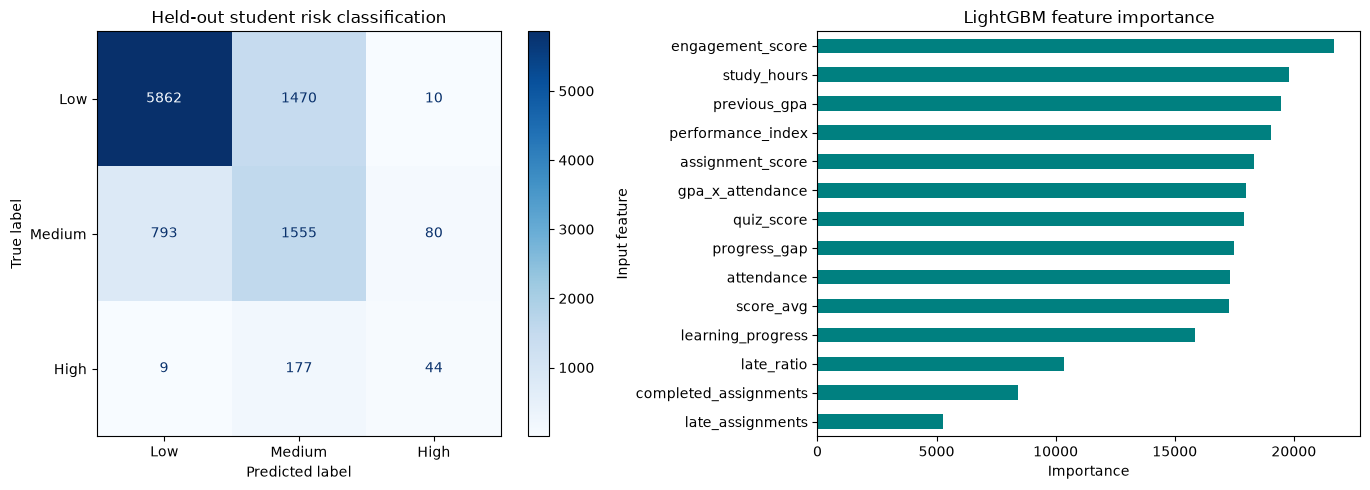

In [95]:
# ============================================================
# VISUALIZE HELD-OUT RESULTS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["Low", "Medium", "High"],
    cmap="Blues", values_format="d", ax=axes[0]
)
axes[0].set_title("Held-out student risk classification")

classifier = evaluation_model.named_steps["classifier"]
importance = pd.Series(classifier.feature_importances_, index=MODEL_FEATURES).sort_values()
importance.plot.barh(ax=axes[1], color="teal", title="LightGBM feature importance")
axes[1].set_xlabel("Importance")
axes[1].set_ylabel("Input feature")

plt.tight_layout()
plt.show()


## Refit on all labeled rows and save

In [96]:
# ============================================================
# TRAIN FINAL MODEL ON ALL DATA AND SAVE ARTIFACT
# ============================================================

counts_all = Counter(y)
total_all = len(y)
class_weight_all = {cls: total_all / (3 * cnt) for cls, cnt in counts_all.items()}

model = make_model(class_weight=class_weight_all)
model.fit(X, y)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_FILE)
if not MODEL_FILE.is_file():
    raise OSError(f"Model file was not created: {MODEL_FILE}")

final_train_acc = accuracy_score(y, model.predict(X))

print("=" * 72)
print("FINAL MODEL SAVED")
print("=" * 72)
print(f"Path           : {MODEL_FILE.resolve()}")
print(f"Size           : {MODEL_FILE.stat().st_size:,} bytes")
print(f"Train rows     : {len(X):,}")
print(f"Train accuracy : {final_train_acc:.4f}")
print("Classes        :", list(model.classes_))


FINAL MODEL SAVED
Path           : D:\Research\new\EduPulse\EduPulse\python\RiskAssessment\ModelOutput\risk_model.joblib
Size           : 24,354,504 bytes
Train rows     : 50,000
Train accuracy : 0.9076
Classes        : ['High', 'Low', 'Medium']
